# 02 - CNN Baseline (Model Engineer 1)
**Proyek:** Diagnosis Dini Penyakit Daun Padi

Notebook ini melatih CNN sederhana **dari nol** sebagai pembanding EfficientNetB0.
1. Menyiapkan repo dan data (hasil notebook 01).
2. Memeriksa pipeline data.
3. Membangun dan melatih CNN (seed utama 42).
4. Plot kurva training dan cek di data **validasi**.
5. Melatih 3 seed + ablasi tanpa augmentasi (artefak untuk evaluator).
6. Catatan eksperimen dan ringkasan artefak.

**Aturan:** data test tidak disentuh di notebook ini. Model terbaik dipilih dari `val_loss`.

## 0. Persiapan (Colab)
Aktifkan GPU: **Runtime > Change runtime type > T4 GPU**.

Data olahan (`data/processed/rice_256/`) dan `data/splits.csv` sudah ada di repo. Unduh repo sebagai zip
(GitHub: **Code > Download ZIP**), lalu jalankan sel di bawah dan pilih zip tersebut, atau seret zip ke panel **Files**
sebelum menjalankan sel. Bila notebook dijalankan lokal dari folder `notebooks/`, bagian Colab otomatis dilewati.

In [2]:
import os, sys, glob, zipfile, shutil
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not Path("/content/repo").exists():
        zips = glob.glob("/content/*.zip")
        if not zips:                                   # belum ada zip -> pilih dari laptop
            from google.colab import files
            uploaded = files.upload()
            zips = []
            for name, data in uploaded.items():
                Path(f"/content/{name}").write_bytes(data)
                zips.append(f"/content/{name}")
        with zipfile.ZipFile(zips[0]) as z:
            z.extractall("/content/unzip_tmp")
        folder = [p for p in Path("/content/unzip_tmp").iterdir() if p.is_dir()][0]
        shutil.move(str(folder), "/content/repo")
    os.chdir("/content/repo/notebooks")

REPO = Path.cwd().parent
sys.path.append(str(REPO))
print("Repo:", REPO)
print("splits.csv ada:", (REPO / "data/splits.csv").exists())
print("gambar ada   :", (REPO / "data/processed/rice_256").exists())

Saving Deeplearning_rice_disease_prediction-main.zip to Deeplearning_rice_disease_prediction-main.zip
Repo: /content/repo
splits.csv ada: True
gambar ada   : True


In [17]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from src.data import data_utils as du
from src.data.data_utils import make_dataset, CLASS_NAMES, NUM_CLASSES, SEED
from src.models.cnn_baseline import (build_cnn, train_cnn, plot_history, compute_class_weights,
                                     DEFAULT_CONFIG, MODELS_DIR, REPORTS_DIR, FIGURES_DIR)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))
print("Kelas:", CLASS_NAMES)

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Kelas: ['Bacterial Leaf Blight', 'Brown Spot', 'Healthy Rice Leaf', 'Leaf Blast', 'Leaf scald', 'Sheath Blight']


## 1. Cek pipeline data
Pastikan bentuk batch (32, 224, 224, 3), rentang piksel 0-255, dan label integer 0-5.

In [18]:
train_ds = make_dataset("train")
val_ds = make_dataset("val")
x, y = next(iter(train_ds))
print("batch:", x.shape, "| min/max piksel:", float(tf.reduce_min(x)), float(tf.reduce_max(x)))
print("label:", y.numpy()[:10])

d = pd.read_csv(du.SPLITS_CSV)
print(pd.crosstab(d.label, d.split, margins=True))

batch: (32, 224, 224, 3) | min/max piksel: 0.0 255.0
label: [0 1 0 2 2 2 3 5 2 4]
split                  test  train  val   All
label                                        
Bacterial Leaf Blight    13    205   14   232
Brown Spot               22    223   23   268
Healthy Rice Leaf        32    345   29   406
Leaf Blast               16    149   18   183
Leaf scald               11    156   12   179
Sheath Blight            43    357   44   444
All                     137   1435  140  1712


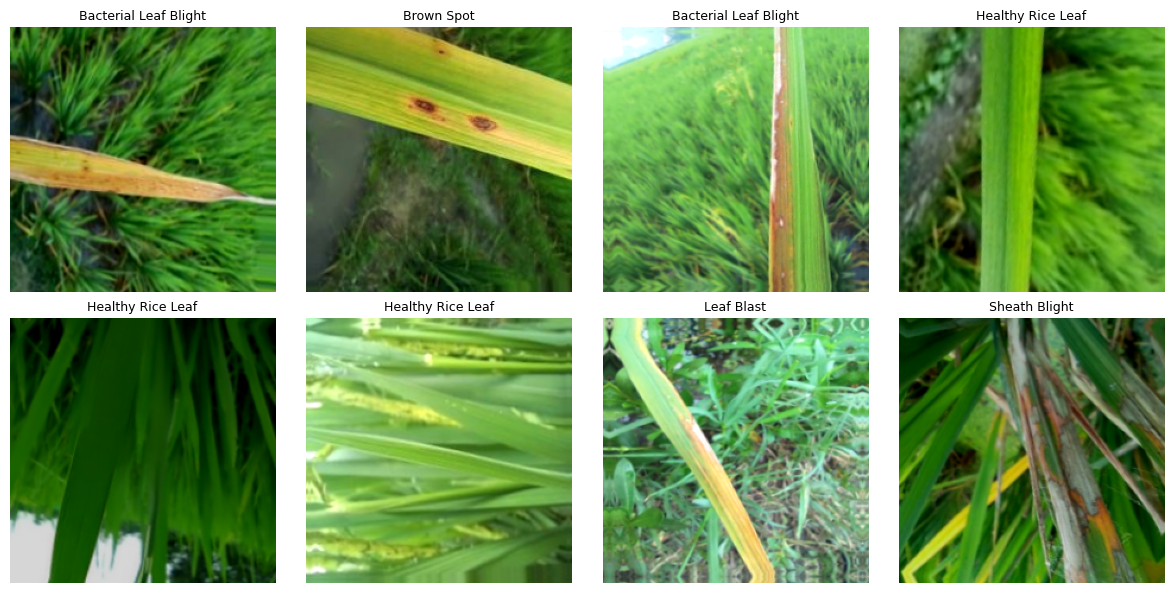

In [19]:
# Contoh gambar train setelah augmentasi
plt.figure(figsize=(12, 6))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(x[i].numpy().astype("uint8"))
    plt.title(CLASS_NAMES[int(y[i])], fontsize=9)
    plt.axis("off")
plt.tight_layout(); plt.show()

### Bobot kelas
Data train tidak seimbang (Sheath Blight 357 vs Leaf Blast 149), jadi loss diberi bobot `balanced`
agar kelas kecil tidak diabaikan.

In [20]:
cw = compute_class_weights()
pd.DataFrame({"kelas": CLASS_NAMES, "bobot": [round(cw[i], 3) for i in range(NUM_CLASSES)]})

,kelas,bobot
0,Bacterial Leaf Blight,1.167
1,Brown Spot,1.072
2,Healthy Rice Leaf,0.693
3,Leaf Blast,1.605
4,Leaf scald,1.533
5,Sheath Blight,0.670


## 2. Arsitektur CNN baseline
- Input 224x224x3 (0-255) -> `Rescaling(1/255)`
- 4 blok: [Conv3x3 -> BatchNorm (momentum 0.9) -> ReLU] x2 -> MaxPool, filter 32/64/128/256
- GlobalAveragePooling -> Dropout 0.5 -> Dense 128 ReLU -> Dropout 0.5 -> Dense 6 softmax
- Regularisasi L2 1e-4 pada Conv dan Dense

GlobalAveragePooling dipakai (bukan Flatten) agar jumlah parameter kecil, karena data latih hanya ~1.400 gambar.

In [21]:
model = build_cnn()
model.summary()
# Konfigurasi lengkap tiap run tercatat di reports/cnn_baseline_*_config.json

Model: "cnn_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gambar (InputLayer)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalisasi (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ blok1_conv1 (Conv2D)            │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ blok1_bn1 (BatchNormalization)  │ (None, 224, 224, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ blok1_relu1 (ReLU)              │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ blok1_conv2 (Conv2D)            │ (None, 224, 224, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ blok1_bn2 (BatchNormalization)  │ (None, 224, 224, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ blok1_relu2 (ReLU)              │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ blok1_pool (MaxPooling2D)       │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ blok2_conv1 (Conv2D)            │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ blok2_bn1 (BatchNormalization)  │ (None, 112, 112, 64)   │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ blok2_relu1 (ReLU)              │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ blok2_conv2 (Conv2D)            │ (None, 112, 112, 64)   │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ blok2_bn2 (BatchNormalization)  │ (None, 112, 112, 64)   │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ blok2_relu2 (ReLU)              │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ blok2_pool (MaxPooling2D)       │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ blok3_conv1 (Conv2D)            │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ blok3_bn1 (BatchNormalization)  │ (None, 56, 56, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ blok3_relu1 (ReLU)              │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ blok3_conv2 (Conv2D)            │ (None, 56, 56, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ blok3_bn2 (BatchNormalization)  │ (None, 56, 56, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ blok3_relu2 (ReLU)              │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ blok3_pool (MaxPooling2D)       │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ blok4_conv1 (Conv2D)            │ (None, 28, 28, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ blok4_bn1 (BatchNormalization)  │ (None, 28, 28, 256)    │         1,02

 Total params: 1,208,806 (4.61 MB)

 Trainable params: 1,206,886 (4.60 MB)

 Non-trainable params: 1,920 (7.50 KB)

## 3. Training seed utama (42)
Konfigurasi final (lihat bagian 6 untuk riwayat tuning):
- Optimizer Adam, learning rate **3e-4**, loss `sparse_categorical_crossentropy`, batch 32
- Maksimal **100 epoch**; `EarlyStopping` (patience **20**, restore best) dan `ModelCheckpoint` memantau `val_loss`
- `ReduceLROnPlateau`: learning rate x0.5 bila `val_loss` stagnan **3** epoch
- Augmentasi data train dan bobot kelas aktif

In [26]:
model, history, cfg = train_cnn(seed=SEED)
print(json.dumps({k: cfg[k] for k in ["best_epoch", "epochs_run", "val_loss", "val_accuracy", "n_params"]}, indent=2))

Epoch 1/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 39s 588ms/step - accuracy: 0.3275 - loss: 1.9570 - val_accuracy: 0.2500 - val_loss: 2.1756 - learning_rate: 3.0000e-04
Epoch 2/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 27s 446ms/step - accuracy: 0.5003 - loss: 1.5088 - val_accuracy: 0.4000 - val_loss: 1.7321 - learning_rate: 3.0000e-04
Epoch 3/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 18s 390ms/step - accuracy: 0.5770 - loss: 1.3199 - val_accuracy: 0.4500 - val_loss: 1.6716 - learning_rate: 3.0000e-04
Epoch 4/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 18s 398ms/step - accuracy: 0.6328 - loss: 1.2030 - val_accuracy: 0.5500 - val_loss: 1.4072 - learning_rate: 3.0000e-04
Epoch 5/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 19s 396ms/step - accuracy: 0.6488 - loss: 1.1862 - val_accuracy: 0.6714 - val_loss: 1.2531 - learning_rate: 3.0000e-04
Epoch 6/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 20s 388ms/step - accuracy: 0.6362 - loss: 1.1697 - val_accuracy: 0.7000 - val_loss: 1.0544 - learning_rate: 3.0000e-04
Epoch 7/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 19s 407ms/ste

In [27]:
# Salinan model utama dengan nama tetap (dipakai evaluator / aplikasi)
shutil.copy(MODELS_DIR / f"cnn_baseline_seed{SEED}.keras", MODELS_DIR / "cnn_baseline.keras")

PosixPath('/content/repo/models/cnn_baseline.keras')

## 4. Kurva training

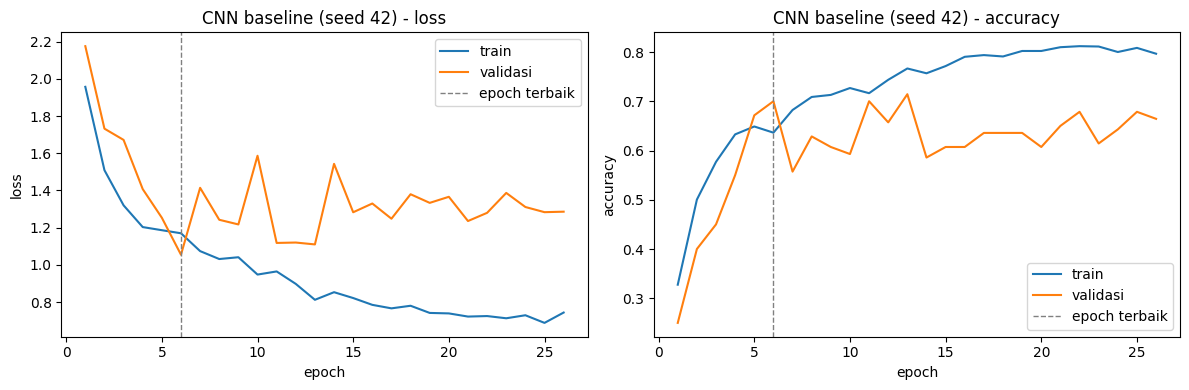

In [28]:
plot_history(REPORTS_DIR / f"cnn_baseline_seed{SEED}_history.csv",
             FIGURES_DIR / f"cnn_baseline_curves_seed{SEED}.png",
             title=f"CNN baseline (seed {SEED})")
plt.show()

**Cara membaca:** bila loss train terus turun tetapi loss validasi naik atau datar, model overfit
(EarlyStopping sudah mengembalikan bobot terbaik). Kurva validasi bergelombang sebagian karena data validasi
hanya 140 gambar (1 gambar = 0,7%).

### Cek mode inference
Membandingkan akurasi train tanpa augmentasi dan validasi dalam mode inference (BatchNorm memakai moving average).
Bila akurasi train di sini jauh di bawah akurasi train saat training, statistik BatchNorm belum stabil.

In [29]:
train_noaug = make_dataset("train", augment=False)
print("train (mode inference) [loss, acc]:", model.evaluate(train_noaug, verbose=0))
print("val   (mode inference) [loss, acc]:", model.evaluate(make_dataset("val"), verbose=0))

train (mode inference): [0.7449954748153687, 0.8027874827384949]
val   (mode inference): [1.0544391870498657, 0.699999988079071]


### Cek cepat di data validasi
Hanya untuk sanity check. Evaluasi resmi di data test dilakukan evaluator dengan protokol yang sama untuk kedua model.

                       precision    recall  f1-score   support

Bacterial Leaf Blight      0.667     0.429     0.522        14
           Brown Spot      0.625     0.435     0.513        23
    Healthy Rice Leaf      0.703     0.897     0.788        29
           Leaf Blast      0.500     0.389     0.438        18
           Leaf scald      0.636     0.583     0.609        12
        Sheath Blight      0.792     0.955     0.866        44

             accuracy                          0.700       140
            macro avg      0.654     0.614     0.622       140
         weighted avg      0.683     0.700     0.680       140



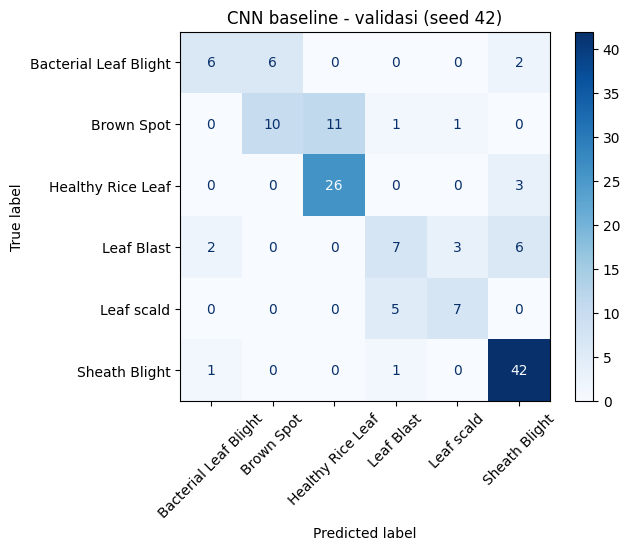

In [30]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

y_val = du.split_labels("val")
p_val = model.predict(make_dataset("val"), verbose=0).argmax(1)
print(classification_report(y_val, p_val, target_names=CLASS_NAMES, digits=3))
ConfusionMatrixDisplay(confusion_matrix(y_val, p_val), display_labels=CLASS_NAMES).plot(
    xticks_rotation=45, cmap="Blues")
plt.title("CNN baseline - validasi (seed 42)"); plt.show()

## 5. Tiga seed + ablasi augmentasi
Evaluator butuh minimal 3 seed. Sel ini melatih seed 42, 123, 2024 (run yang sudah ada dilewati)
dan versi tanpa augmentasi untuk studi ablasi. Di GPU T4 seluruhnya sekitar 30-60 menit; tidak ada progress bar
(`verbose=0`), pantau file `*_config.json` baru di `reports/`.

In [31]:
SEEDS = [42, 123, 2024]
RUN_ABLATION = True

rows = []
for s in SEEDS:
    cfg_path = REPORTS_DIR / f"cnn_baseline_seed{s}_config.json"
    if not cfg_path.exists():
        tf.keras.backend.clear_session()
        train_cnn(seed=s, verbose=0)
    rows.append(json.load(open(cfg_path)))
    if RUN_ABLATION:
        tag = f"cnn_baseline_noaug_seed{s}"
        ab_path = REPORTS_DIR / f"{tag}_config.json"
        if not ab_path.exists():
            tf.keras.backend.clear_session()
            train_cnn(seed=s, tag=tag, augment=False, verbose=0)
        rows.append(json.load(open(ab_path)))

ringkas = pd.DataFrame(rows)[["tag", "seed", "augment", "best_epoch", "epochs_run", "val_loss", "val_accuracy"]]
ringkas.to_csv(REPORTS_DIR / "cnn_baseline_runs.csv", index=False)
print(ringkas.to_string(index=False))
print()
print(ringkas.groupby("augment")["val_accuracy"].agg(["mean", "std"]))

                        tag  seed  augment  best_epoch  epochs_run  val_loss  val_accuracy
        cnn_baseline_seed42    42     True           6          26  1.054439      0.700000
  cnn_baseline_noaug_seed42    42    False          12          32  1.116407      0.600000
       cnn_baseline_seed123   123     True          10          30  1.005378      0.707143
 cnn_baseline_noaug_seed123   123    False           7          27  1.017680      0.614286
      cnn_baseline_seed2024  2024     True          15          35  1.044938      0.650000
cnn_baseline_noaug_seed2024  2024    False          10          30  0.908097      0.664286

             mean       std
augment                    
False    0.626190  0.033756
True     0.685714  0.031135


## 6. Catatan eksperimen
Riwayat tuning (seed 42, dinilai di data validasi):

| Run | Perubahan | Hasil validasi | Keputusan |
|---|---|---|---|
| 1 | Awal: BatchNorm momentum 0.99, lr 1e-3, patience 10 | akurasi ~0,25, epoch terbaik 1 | statistik BatchNorm belum stabil |
| 2 | BatchNorm momentum 0.9, maks 100 epoch, patience 20 | akurasi ~0,72, val_loss 1,07 (epoch 36), kurva sangat bergelombang | belajar, tetapi tidak stabil |
| 3 | lr 3e-4, ReduceLROnPlateau patience 3 | akurasi 0,700, val_loss 1,05 (epoch 6), kurva lebih stabil | **konfigurasi final** |

Run 2 dan 3 setara (selisih ~3 gambar validasi); run 3 dipilih karena lebih stabil dan lebih cepat.
Tuning dihentikan agar tidak overfit ke 140 gambar validasi.

Hasil 3 seed (akurasi validasi): dengan augmentasi **0,686 ± 0,031**, tanpa augmentasi **0,626 ± 0,034**.
Augmentasi cenderung membantu (lebih baik di seed 42 dan 123, tidak di seed 2024).

## 7. Ringkasan untuk anggota lain
| Artefak | Lokasi |
|---|---|
| Model utama | `models/cnn_baseline.keras` |
| Model per seed | `models/cnn_baseline_seed{42,123,2024}.keras` |
| Model ablasi (tanpa augmentasi) | `models/cnn_baseline_noaug_seed*.keras` |
| History per run | `reports/cnn_baseline_*_history.csv` |
| Konfigurasi + versi + urutan kelas | `reports/cnn_baseline_*_config.json` |
| Ringkasan semua run | `reports/cnn_baseline_runs.csv` |
| Kurva training | `reports/figures/cnn_baseline_curves_seed42.png` |

```python
from tensorflow import keras
model = keras.models.load_model("models/cnn_baseline.keras")   # input 0-255, normalisasi di dalam model
probs = model.predict(du.load_for_inference(pil_image))         # urutan kelas = du.CLASS_NAMES
```

## 8. (Colab) Unduh semua hasil
File `.keras` jangan di-commit ke GitHub (`models/` di-ignore); bagikan lewat Google Drive.
CSV, JSON, dan gambar di `reports/` boleh di-commit. Notebook ini sendiri diunduh lewat **File > Download > .ipynb**.

In [ ]:
if IN_COLAB:
    with zipfile.ZipFile("/content/hasil_cnn_baseline.zip", "w", zipfile.ZIP_DEFLATED) as z:
        for sub in ["models", "reports", "src/models"]:
            for f in Path("/content/repo", sub).rglob("*"):
                if f.is_file():
                    z.write(f, f.relative_to("/content/repo"))
    from google.colab import files
    files.download("/content/hasil_cnn_baseline.zip")